<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession &mdash; 002 Viterbi Decoder</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Three Makasih

- **Anggota 1** (<span style="color:gray">email</span>)
- **Anggota 2** (<span style="color:gray">email</span>)
- **Anggota 3** (<span style="color:gray">email</span>)

---

## Ringkasan

Baseline resmi memilih tim pemain terdekat ke bola pada tiap frame, lalu meratakannya dengan majority vote. Cara ini punya dua kelemahan yang terlihat pada EDA: label berkedip pada kontes yang ambigu (sepertiga frame berselisih kurang dari 2 m), dan bola yang hilang dianggap bola mati (`D`) padahal sebagian besar gap hanyalah oklusi.

Eksperimen ini mengganti majority vote dengan **decoder Viterbi dua keadaan** (`H`, `A`) yang bobot buktinya lunak dan biaya pergantiannya eksplisit. Saat bola hilang tidak ada bukti, sehingga keadaan **bertahan**. Bola mati ditambahkan terpisah dengan aturan sederhana: gap bola yang berlangsung minimal *G* detik dilabeli `D`. Aturan ini ternyata kasar (lihat Ringkasan).

Tidak ada pelatihan model, tidak ada label tangan, dan ground truth publik tidak dipakai untuk memilih parameter (lihat `RULES.md`). Metrik peringkat tetap **spellF1**.

$$
\hat{s}_{1:T} = \arg\max_{s} \; \sum_{t=1}^{T} \log p(e_t \mid s_t) \;-\; \lambda \sum_{t=2}^{T} \mathbb{1}[s_t \neq s_{t-1}],
\qquad
e_t = \frac{d^{A}_t - d^{H}_t}{\tau}
$$


# Metodologi

**ATD → jarak pemain terdekat tiap tim → bukti lunak *e* → Viterbi H/A (biaya ganti λ) → gap bola panjang menjadi `D` → `X` di luar frame dinilai → `out/*.csv` → validasi → skor GT publik (hanya pemeriksaan pipeline).**

Parameter dipilih dari pertimbangan fisik dan sepak bola, bukan dari ground truth:

| parameter | nilai | alasan |
|---|---|---|
| τ | 3 m | skala jarak ketika selisih tim terdekat mulai bermakna; EDA menunjukkan median jarak terdekat 1,9 m |
| λ | 50 nat | sekitar 2 detik bukti konsisten pada selisih 3 m (≈ 25 nat per detik) |
| G | 8 detik | gap bola lebih pendek hampir pasti oklusi; berhenti permainan biasanya lebih lama |

# Environment

Dijalankan dari dalam repositori. Seluruh pemrosesan lokal; tidak ada data pertandingan yang meninggalkan mesin.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import subprocess
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import common
from baseline import smooth, write_submission
from games import GAME, anchor_video_frame, GAMES, half_video_blocks, source_frames

C1, C2, C3, INK, GREY = "#e94f37", "#393e41", "#f6f7eb", "#393e41", "#a3a7a6"
mpl.rcParams.update({
    "figure.facecolor": C3, "savefig.facecolor": C3, "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titleweight": "bold", "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False, "legend.frameon": False,
    "figure.dpi": 110, "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY]),
})
def panel(ax, l): ax.text(-0.09, 1.07, l, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

FPS = 25
N = source_frames("tactical")
BLOCKS = half_video_blocks("BAR-ATH")
OUT = Path(common.HERE) / "002_viterbi" / "out"
OUT.mkdir(parents=True, exist_ok=True)
print("frames:", N, "| blok dinilai:", BLOCKS)

frames: 199319 | blok dinilai: [(1, 11185, 90651), (2, 110808, 190197)]


# Approach: Viterbi H/A dengan Gap Bola Mati

## [1] Bukti lunak per frame

Untuk tiap frame dengan bola dan pemain kedua tim terlacak, bukti $e = (d^A - d^H)/\tau$ dipotong ke $[-10, 10]$. Peluang tim $H$ adalah sigmoid dari $e$. Frame tanpa bola tidak memberi bukti ($\log p = 0$ untuk kedua tim), sehingga keadaan bertahan.

frame dinilai dengan bukti: 59.2% | tanpa bukti (keadaan bertahan): 40.8%


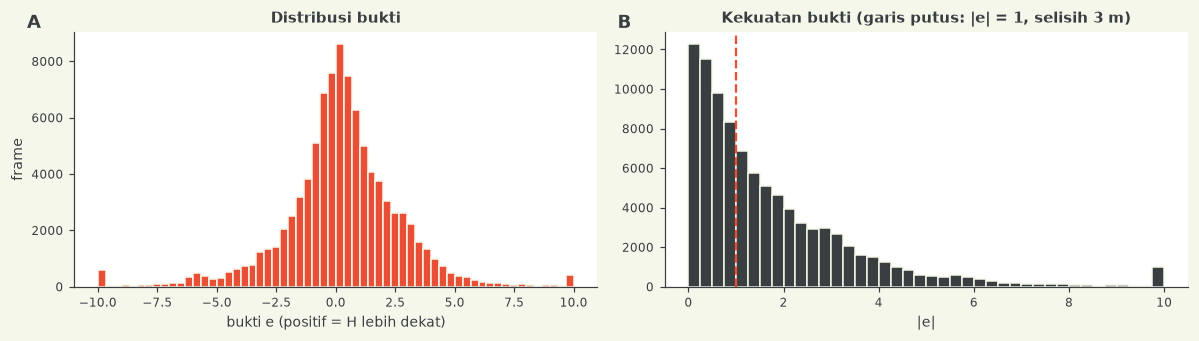

frame dengan |e| < 1 (ambigu): 44.6%


In [2]:
TAU = 3.0
dist = common.team_distances()                                  # (N,2) jarak terdekat H, A
BALL = np.isfinite(common.load_atd_arrays()[1][:, 0])
dH, dA = dist[:, 0], dist[:, 1]
OK = np.isfinite(dH) & np.isfinite(dA)
E = np.zeros(N)
E[OK] = np.clip((dA[OK] - dH[OK]) / TAU, -10, 10)
LP_H, LP_A = -np.logaddexp(0, -E), -np.logaddexp(0, E)
LP_H[~OK] = 0; LP_A[~OK] = 0

GRADED = np.zeros(N, bool)
for _, a, b in BLOCKS: GRADED[a:b + 1] = True
print(f"frame dinilai dengan bukti: {OK[GRADED].mean():.1%} | tanpa bukti (keadaan bertahan): {(~OK[GRADED]).mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(E[OK & GRADED], bins=60, color=C1, edgecolor=C3); ax[0].set(xlabel="bukti e (positif = H lebih dekat)", ylabel="frame", title="Distribusi bukti")
w = np.abs(E[OK & GRADED]); ax[1].hist(w, bins=40, color=C2, edgecolor=C3)
ax[1].axvline(1, color=C1, ls="--"); ax[1].set(xlabel="|e|", title="Kekuatan bukti (garis putus: |e| = 1, selisih 3 m)")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()
print(f"frame dengan |e| < 1 (ambigu): {np.mean(w < 1):.1%}")

Bukti terkonsentrasi di dekat nol: banyak frame hampir tidak membedakan kedua tim. Majority vote memperlakukan setiap frame sama; Viterbi membiarkan bukti kuat menang atas bukti lemah dan hanya berpindah ketika bukti terkumpul melampaui biaya ganti λ.

## [2] Decoder dan aturan bola mati

Keluaran dibangun per babak. Di dalam babak: Viterbi H/A pada semua frame (frame tanpa bukti hanya mewariskan keadaan). Setelah itu, gap bola yang berlangsung minimal *G* detik ditimpa dengan `D`. Dua aturan tambahan berasal dari batas yang dipublikasikan, bukan dari label: frame di luar dua babak adalah `X`, dan frame babak kedua sebelum kick-off (110.808 sampai 113.741) adalah `D`.

In [3]:
KICKOFF2 = anchor_video_frame(GAMES[GAME]["kickoff_2nd"]) + 1     # FAQ: babak 2 dinilai dari 110.808, kick-off 113.742
assert KICKOFF2 == 113742, KICKOFF2

def decode(lam, gap_s=None):
    labels = np.full(N, "X", dtype="<U1")
    for half, a, b in BLOCKS:
        path = common.viterbi_2state(LP_H[a:b + 1], LP_A[a:b + 1], lam)
        labels[a:b + 1] = np.where(path == 0, "H", "A")
        if gap_s:
            s, e = common.runs(~BALL[a:b + 1])
            for si, ei in zip(s, e):
                if (ei - si) >= gap_s * FPS:
                    labels[a + si:a + ei] = "D"
        if half == 2:
            labels[a:KICKOFF2] = "D"
    return labels

def possessions(labels):
    """Jumlah run maksimal H atau A pada frame dinilai (D memutus possession)."""
    n, durs = 0, []
    for _, a, b in BLOCKS:
        seg = labels[a:b + 1]
        for t in ("H", "A"):
            s, e = common.runs(seg == t)
            n += len(s); durs += list((e - s) / FPS)
    return n, float(np.mean(durs))

demo = decode(50, 8)
print(pd.Series(demo[GRADED]).value_counts().to_string())
print("possession: %d | durasi rata-rata %.1f dtk" % possessions(demo))

D    60865
H    56371
A    41621
possession: 243 | durasi rata-rata 16.1 dtk


Aturan G = 8 detik melabeli sekitar 38% frame dinilai sebagai `D`. Itu jauh lebih banyak daripada porsi bola mati yang wajar (ground truth publik 5 menit hanya sekitar 20% `D`), karena sebagian besar gap bola adalah oklusi, bukan henti permainan. Jumlah possession dan durasi rata-rata dapat dibandingkan dengan baseline tanpa menyentuh ground truth.

## [3] Varian yang dibangun

Empat varian ditulis ke `out/`. Tiga di antaranya mengubah satu parameter dari konfigurasi dasar (λ = 50, G = 8) agar pengaruhnya bisa dibaca. Baseline `smooth50` ditulis ulang agar muncul pada papan yang sama.

In [4]:
VARIANTS = {
    "v1_lam50_hold": (50, None),     # tanpa aturan D selain pra-kick-off
    "v2_lam50_gap8": (50, 8),        # konfigurasi dasar
    "v3_lam25_gap8": (25, 8),
    "v4_lam100_gap8": (100, 8),
}
for old in OUT.glob("*.csv"): old.unlink()
rows = []
for name, (lam, g) in VARIANTS.items():
    lab = decode(lam, g)
    write_submission(str(OUT / f"{name}.csv"), lab)
    n, d = possessions(lab)
    rows.append({"varian": name, "lambda": lam, "G (dtk)": g, "possession": n, "durasi rata2 (dtk)": round(d, 1),
                 "% D (dinilai)": round(100 * np.mean(lab[GRADED] == "D"), 1)})

codes = common.cached("atd_nearest", lambda: None)
base = np.full(N, "X", dtype="<U1")
sm = smooth(codes, 50)
for _, a, b in BLOCKS: base[a:b + 1] = sm[a:b + 1]
write_submission(str(OUT / "baseline_smooth50.csv"), base)
n, d = possessions(base)
rows.append({"varian": "baseline_smooth50", "lambda": None, "G (dtk)": None, "possession": n,
             "durasi rata2 (dtk)": round(d, 1), "% D (dinilai)": round(100 * np.mean(base[GRADED] == "D"), 1)})
stats = pd.DataFrame(rows); display(stats)

,varian,lambda,G (dtk),possession,durasi rata2 (dtk),% D (dinilai)
0,v1_lam50_hold,50.0,NaN,159,39.2,1.8
1,v2_lam50_gap8,50.0,8.0,243,16.1,38.3
2,v3_lam25_gap8,25.0,8.0,319,12.3,38.3
3,v4_lam100_gap8,100.0,8.0,192,20.4,38.3
4,baseline_smooth50,NaN,NaN,594,7.2,32.3


Baseline `smooth50` menghasilkan jauh lebih banyak possession daripada varian Viterbi dengan durasi rata-rata jauh lebih pendek. Ini sejalan dengan temuan README bahwa flicker adalah penyebab utama spellF1 rendah.

## [4] Validasi dan skor (pemeriksaan pipeline)

Setiap berkas divalidasi dengan skrip resmi, lalu dinilai pada ground truth publik 5 menit. Skor ini **tidak** dipakai untuk memilih varian: 17 possession tidak cukup, dan README menunjukkan bahwa tuning pada jendela ini memilih parameter yang salah.

In [5]:
for f in sorted(OUT.glob("*.csv")):
    r = subprocess.run([sys.executable, str(ROOT / "evaluation" / "validate_submission.py"), str(f)], capture_output=True, text=True)
    print(f.name, "->", "VALID" if "Valid." in r.stdout else r.stdout[-200:])

subprocess.run([sys.executable, str(ROOT / "evaluation" / "run_evaluation.py"), "--results", str(OUT),
                "--out", str(OUT / "reports")], capture_output=True, text=True)
board = pd.read_csv(OUT / "reports" / "scoreboard.csv")
display(board[["rank", "submission", "macro_f1", "spell_f1_mean", "poss", "dur"]].round(4))

baseline_smooth50.csv -> VALID


v1_lam50_hold.csv -> VALID


v2_lam50_gap8.csv -> VALID


v3_lam25_gap8.csv -> VALID


v4_lam100_gap8.csv -> VALID


,rank,submission,macro_f1,spell_f1_mean,poss,dur
0,1,v3_lam25_gap8,0.6197,0.3889,19,14.5305
1,2,v2_lam50_gap8,0.6279,0.3704,10,27.6080
2,3,baseline_smooth50,0.6207,0.3256,26,10.8031
3,4,v1_lam50_hold,0.5111,0.3200,8,37.5000
4,5,v4_lam100_gap8,0.6264,0.2880,8,34.5100


## [5] Sensitivitas parameter (tanpa ground truth)

Untuk melihat seberapa stabil hasilnya, jumlah possession prediksi disapu terhadap λ dan *G*. Ini hanya ukuran internal: kestabilan terhadap parameter, bukan akurasi.

,tanpa D,G=3s,G=5s,G=8s,G=12s,G=20s
λ=10,448,556,556,522,499,485
λ=25,238,355,355,319,293,277
λ=50,159,279,279,243,215,199
λ=100,107,228,228,192,164,148
λ=200,75,196,196,160,132,116
λ=400,32,158,158,120,91,74


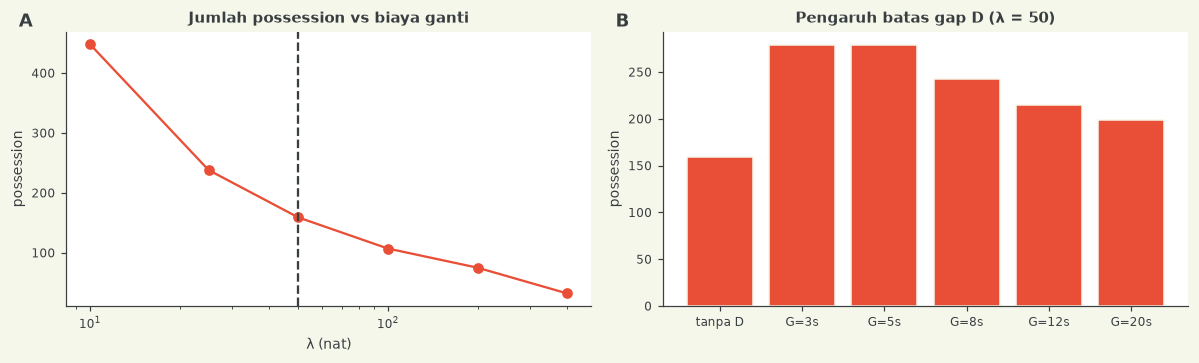

In [6]:
lams = [10, 25, 50, 100, 200, 400]
gaps = [None, 3, 5, 8, 12, 20]
grid = pd.DataFrame([[possessions(decode(l, g))[0] for g in gaps] for l in lams],
                    index=[f"λ={l}" for l in lams], columns=["tanpa D" if g is None else f"G={g}s" for g in gaps])
display(grid)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(lams, grid.iloc[:, 0], marker="o", color=C1); ax[0].set(xscale="log", xlabel="λ (nat)", ylabel="possession", title="Jumlah possession vs biaya ganti")
ax[0].axvline(50, color=C2, ls="--")
lam50 = grid.loc["λ=50"]; ax[1].bar(range(len(lam50)), lam50.values, color=C1, edgecolor=C3)
ax[1].set(xticks=range(len(lam50)), xticklabels=lam50.index, ylabel="possession", title="Pengaruh batas gap D (λ = 50)")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

# Ringkasan 002

**Yang dikerjakan.** Majority vote baseline diganti Viterbi H/A dengan bukti lunak (τ = 3 m) dan biaya ganti λ; gap bola ≥ *G* detik menjadi `D`; frame di luar babak `X`; 2.934 frame pra-kick-off babak kedua `D`. Semua berkas lolos `validate_submission.py`.

**Hasil pemeriksaan pipeline (GT publik, 17 possession; bukan dasar pemilihan).** `v3_lam25_gap8` 0,389, `v2_lam50_gap8` 0,370, `baseline_smooth50` 0,326, `v1_lam50_hold` 0,320, `v4_lam100_gap8` 0,288 pada spellF1. Selisih antar varian berada dalam noise sampel 5 menit (satu possession meleset menggeser sekitar enam poin), jadi **tidak ada klaim bahwa decoder ini lebih baik daripada baseline**. Varian terbaik pada jendela ini bahkan bukan konfigurasi dasar, dan README menunjukkan bahwa memilih parameter dari jendela ini menghasilkan pilihan yang salah.

**Temuan yang bisa dipegang.**
1. Pada 44,6% frame dinilai yang punya bukti, |e| < 1: kurang dari separuh frame benar-benar membedakan kedua tim.
2. Viterbi menghasilkan jauh lebih sedikit possession dengan durasi lebih panjang daripada `smooth50` (243 vs 594 pada konfigurasi dasar), artinya flicker teredam.
3. Jumlah possession sangat sensitif terhadap λ (448 pada λ = 10 sampai 32 pada λ = 400 tanpa aturan D). Tidak ada cara memilih λ dari data tanpa ground truth, jadi λ = 50 tetap tebakan berbasis prior (sekitar 2 detik bukti konsisten).
4. **Aturan gap → `D` terlalu kasar.** Ia menandai sekitar 38% frame dinilai sebagai `D`, jauh di atas porsi bola mati yang wajar, dan memecah possession pada tiap oklusi panjang. Tanpa aturan ini (`v1`) kelas `D` hampir kosong dan macroF1 turun ke 0,51.

**Langkah berikutnya (003).** Ganti aturan gap dengan deteksi bola mati yang sebenarnya: restart Smart Tagging (`SET PIECES`), gerak kolektif pemain, dan bola di luar batas lapangan; gap bola saja tidak cukup. Parameter λ juga perlu pembenaran selain prior, misalnya dari distribusi durasi possession pertandingan lain.